# Both strategies on both datasets: airports and football

**Airports** (`airports-v5`, 243 context-on / 180 context-off tasks, hidden properties of `Airport` nodes) and
**football** (`football-v1-idmix`, 239 / 233 tasks, hidden properties of `Player` nodes). Same 5 models,
3 runs, same prompts (Strategy A: 9 prompts) and the same agent (Strategy B: search, and search + memory, run on
the context-on sets). This report puts the two datasets side by side to separate what holds in general from
what depends on the graph.

**Scoring.** Each task hides one property. The answer of a configuration (model, prompt or approach) is the vote over
its 3 runs (text: most frequent value; numbers: mean; abstained only when all 3 runs abstain), and is **correct**,
**wrong** or **abstained**. **F1** = 2c / (2c + 2w + a) counts abstentions against recall; **F1 (abstentions ignored)**
= 2c / (2c + w) scores only the answers given (the paper's Table 3 scoring). Intervals are 95% bootstrap intervals
over tasks (1,000 resamples); paired differences resample the same tasks for both sides; task-by-task comparisons use
an exact McNemar test on "correct".

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd() if Path.cwd().name == "notebooks" else Path.cwd() / "notebooks"))
from paper_report_lib import *
FOLDER = "both"

v = load_voted(("airports", "ctx"), ("airports", "noctx"), ("football", "ctx"), ("football", "noctx"))
runs = load_runs(("airports", "ctx"), ("football", "ctx"))
eff = load_effort()
DS = ["airports", "football"]
ctx = v[v.set == "ctx"].copy()
mp = metrics(ctx[ctx.strategy == "A"], ["dataset", "model", "approach"])
BEST = mp.loc[mp.groupby(["dataset", "model"]).f1.idxmax()].set_index(["dataset", "model"]).approach.to_dict()
def cfg(r):
    if r.strategy == "A":
        return "A best" if r.approach == BEST[(r.dataset, r.model)] else ("A zero-shot" if r.approach == "zero" else None)
    return "B search" if r.approach == "search_evidence" else "B search + memory"
ctx["cfg"] = ctx.apply(cfg, axis=1)
C = ["A zero-shot", "A best", "B search", "B search + memory"]
CC = {"A zero-shot": "#cde2fb", "A best": "#86b6ef", "A mean": "#c9c8c2", "B search": "#eb6834", "B search + memory": "#a8380c"}
print(v.groupby(["dataset", "set"]).task_id.nunique().to_dict())
pd.DataFrame(BEST, index=["best A prompt (F1)"]).T.unstack(0).droplevel(0, axis=1).rename(index=MNAME)

{('airports', 'ctx'): 243, ('airports', 'noctx'): 180, ('football', 'ctx'): 239, ('football', 'noctx'): 233}


,airports,football
deepseek-v4.1-flash,fewcot_5,few_3
gemma4:31b,zerocot,compact
gpt-oss:120b,compact,compact
gpt-oss:20b,fewcot_3,compact
mistral-large-3,fewcot_5,few_5


## 1. Headline numbers

### Score per model, approach and dataset

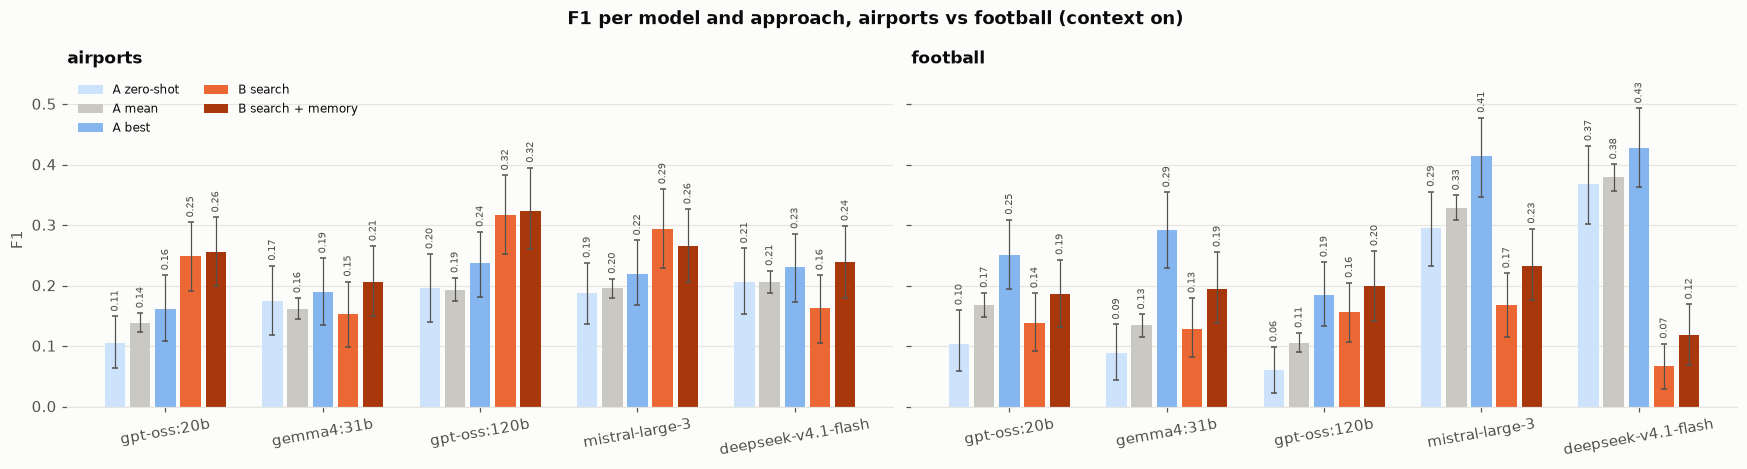

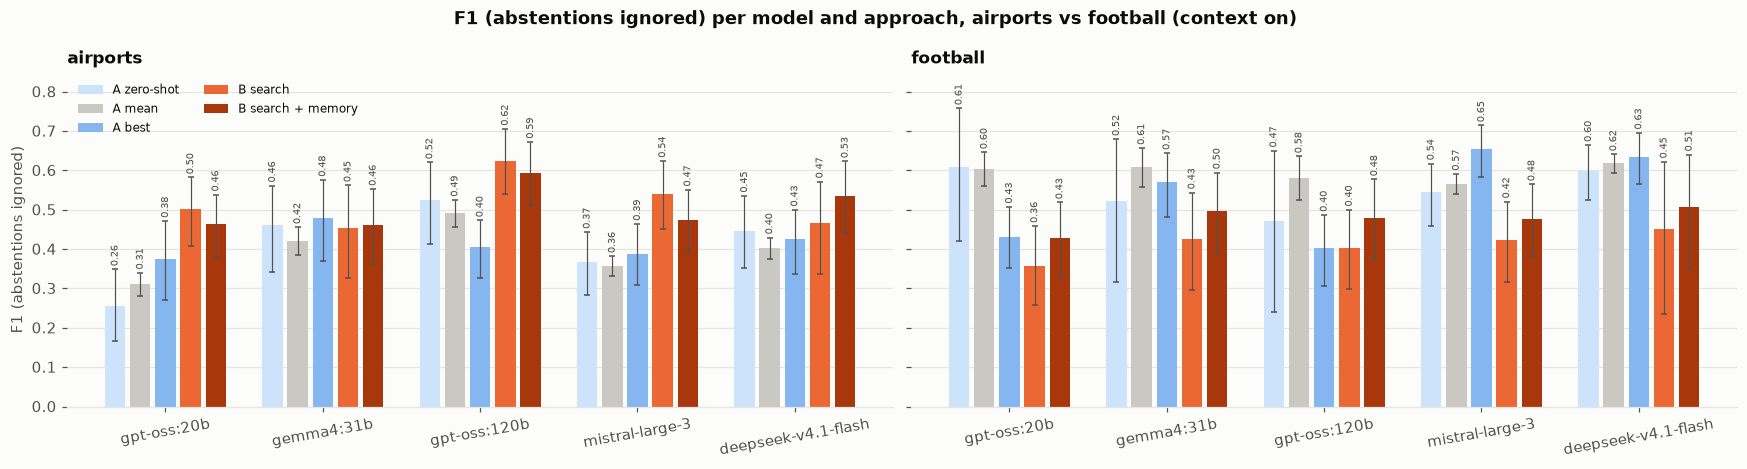

f1                                               f1_ign                                              
cfg                          A best A mean A zero-shot B search B search + memory A best A mean A zero-shot B search B search + memory
dataset  model                                                                                                                        
airports deepseek-v4.1-flash  0.231  0.207       0.206    0.163             0.238  0.426  0.402       0.446    0.466             0.534
         gemma4:31b           0.190  0.161       0.175    0.152             0.205  0.478  0.420       0.462    0.455             0.461
         gpt-oss:120b         0.237  0.193       0.196    0.316             0.324  0.404  0.491       0.524    0.624             0.593
         gpt-oss:20b          0.161  0.138       0.106    0.249             0.256  0.375  0.310       0.256    0.503             0.464
         mistral-large-3      0.219  0.195       0.187    0.294             0.265  0.387  0.357       0.366    0.541             0.475
football deepseek-v4.1-flash  0.428  0.380       0.368    0.067             0.118  0.633  0.618       0.599    0.450             0.507
         gemma4:31b           0.292  0.135       0.088    0.128             0.195  0.570  0.610       0.522    0.426             0.496
         gpt-oss:120b         0.185  0.105       0.060    0.156             0.200  0.402  0.582       0.471    0.403             0.479
         gpt-oss:20b          0.250  0.169       0.103    0.138             0.187  0.430  0.605       0.609    0.358             0.428
         mistral-large-3      0.413  0.329       0.294    0.167             0.232  0.654  0.566       0.545    0.423             0.476

In [2]:
t = pd.concat([boot(ctx[ctx.cfg.notna()], ["dataset", "model", "cfg"]), boot(ctx[ctx.strategy == "A"], ["dataset", "model"]).assign(cfg="A mean")])
order = ["A zero-shot", "A mean", "A best", "B search", "B search + memory"]
for s, n in SCORES:
    fig, axes = plt.subplots(1, 2, figsize=(16, 4.3), sharey=True)
    for ax, d in zip(axes, DS):
        grouped_bars(ax, t[t.dataset == d], "model", MODELS, "cfg", order, s, CC, names=MNAME); ax.set_title(d)
        ax.set_xticklabels(MN, rotation=10)
    axes[0].set_ylabel(n); axes[0].legend(fontsize=8, ncol=2, loc="upper left")
    fig.suptitle(f"{n} per model and approach, airports vs football (context on)")
    save(fig, FOLDER, f"both_headline_{s}")
tab = t.assign(model=t.model.map(MNAME)).pivot_table(index=["dataset", "model"], columns="cfg", values=["f1", "f1_ign"]).round(3)
display(tab)

The two datasets give opposite answers to *does search help?*. On **airports**, a B variant has the highest F1 for four of five models (B + memory 0.21–0.32, B search up to 0.29, against 0.16–0.24 for A best); deepseek ties (B + memory 0.24 vs A best 0.23). On **football**, A best has the highest F1 for four of five models (0.19–0.43 against 0.12–0.23 for B + memory), and only gpt-oss:120b ties. The same agent, models and prompts were used on both, so the difference comes from the data: airport facts (codes, cities, runways) are published in a few standard sources, while player statistics depend on season and competition.

### Football − airports, per model and approach

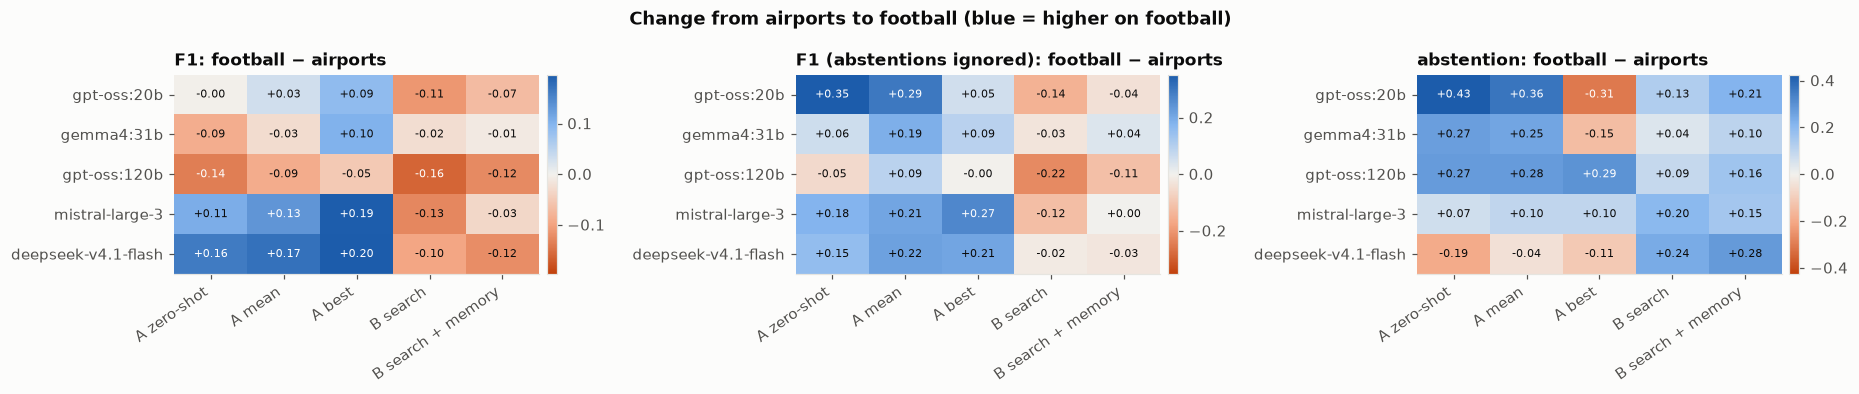

In [3]:
t = pd.concat([metrics(ctx[ctx.cfg.notna()], ["dataset", "model", "cfg"]), metrics(ctx[ctx.strategy == "A"], ["dataset", "model"]).assign(cfg="A mean")])
order = ["A zero-shot", "A mean", "A best", "B search", "B search + memory"]
fig, axes = plt.subplots(1, 3, figsize=(17, 3.6))
for ax, (s, n) in zip(axes, SCORES + [("abstention", "abstention")]):
    pv = t.pivot_table(index="model", columns=["dataset", "cfg"], values=s)
    dlt = (pv["football"] - pv["airports"]).reindex(index=MODELS, columns=order)
    heat(ax, dlt, fmt="{:+.2f}", cmap=DIV, center=0, xlabels=order, ylabels=MN); ax.set_title(f"{n}: football − airports")
fig.suptitle("Change from airports to football (blue = higher on football)")
save(fig, FOLDER, "both_delta")

Going from airports to football, Strategy B loses F1 for every model (search −0.02 to −0.16, memory −0.01 to −0.12), while Strategy A gains for the two models that answer most (mistral and deepseek: A best +0.19/+0.20). F1 ign of A rises on football for most models (+0.05 to +0.35), because football has many properties with typical values that pass the numeric tolerance. Abstention rises on football for B (+0.04 to +0.28) and for A zero-shot of the three cautious models (+0.27 to +0.43).

### Precision against recall: every configuration on both datasets

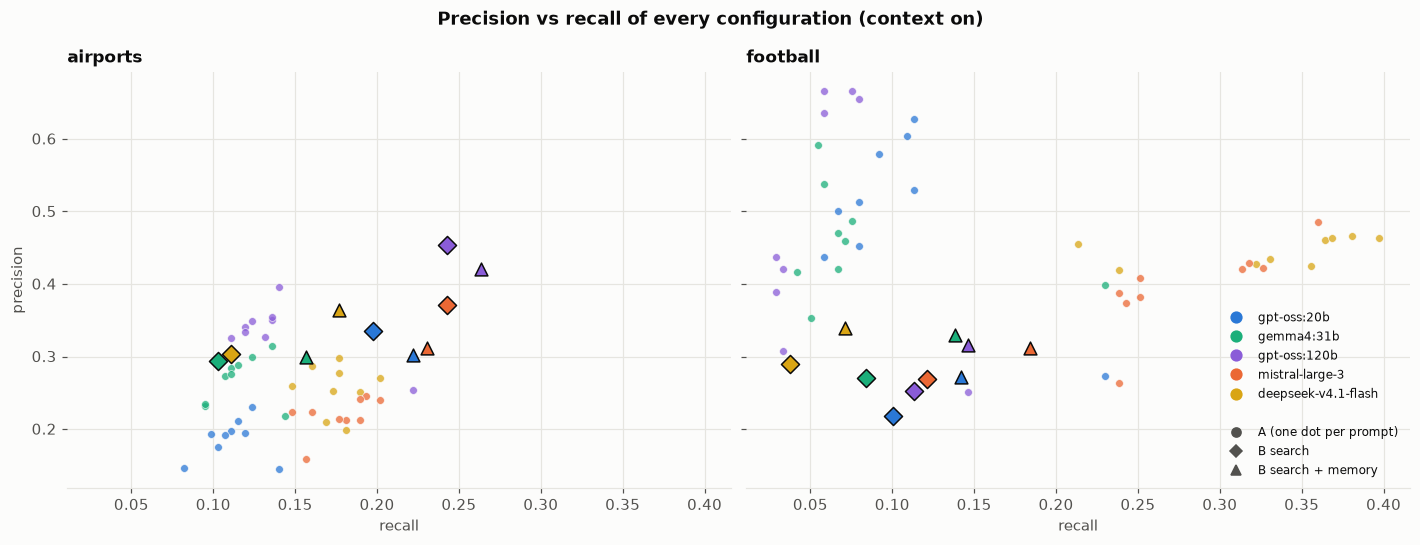

In [4]:
t = metrics(ctx, ["dataset", "model", "approach"])
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, d in zip(axes, DS):
    for _, r in t[t.dataset == d].iterrows():
        mk = "D" if r.approach == "search_evidence" else "^" if r.approach == "search_memory" else "o"
        ax.scatter(r.recall, r.precision, marker=mk, s=70 if mk != "o" else 26, color=MCOLOR[r.model], edgecolor=INK if mk != "o" else SURFACE,
                   linewidth=1 if mk != "o" else 0.5, alpha=1 if mk != "o" else 0.75, zorder=3 if mk != "o" else 2)
    ax.set_title(d); ax.set_xlabel("recall")
axes[0].set_ylabel("precision")
h = model_handles() + [plt.Line2D([], [], ls="", marker="", label="")] + [plt.Line2D([], [], ls="", marker=mk, color=INK2, label=l) for mk, l in
                                                                          (("o", "A (one dot per prompt)"), ("D", "B search"), ("^", "B search + memory"))]
axes[1].legend(handles=h, fontsize=8)
fig.suptitle("Precision vs recall of every configuration (context on)")
save(fig, FOLDER, "both_precision_recall")

Plotting every configuration shows the shift. On airports the B points (diamonds and triangles) sit above and to the right of their model's A prompts for the gpt-oss models and mistral. On football they sit below and to the left of the A cloud for every model. Strategy A's points move to higher precision and, for mistral and deepseek, to much higher recall on football.

## 2. Strategy A: prompts, models and context

### What matters more: the model or the prompt?

,dataset,set,score,span over models (mean over prompts),span over prompts (mean over models)
0,airports,ctx,F1,0.068,0.010
1,airports,ctx,F1 (abstentions ignored),0.188,0.106
2,airports,noctx,F1,0.157,0.034
3,airports,noctx,F1 (abstentions ignored),0.206,0.098
4,football,ctx,F1,0.276,0.092
5,football,ctx,F1 (abstentions ignored),0.096,0.220
6,football,noctx,F1,0.268,0.101
7,football,noctx,F1 (abstentions ignored),0.123,0.192


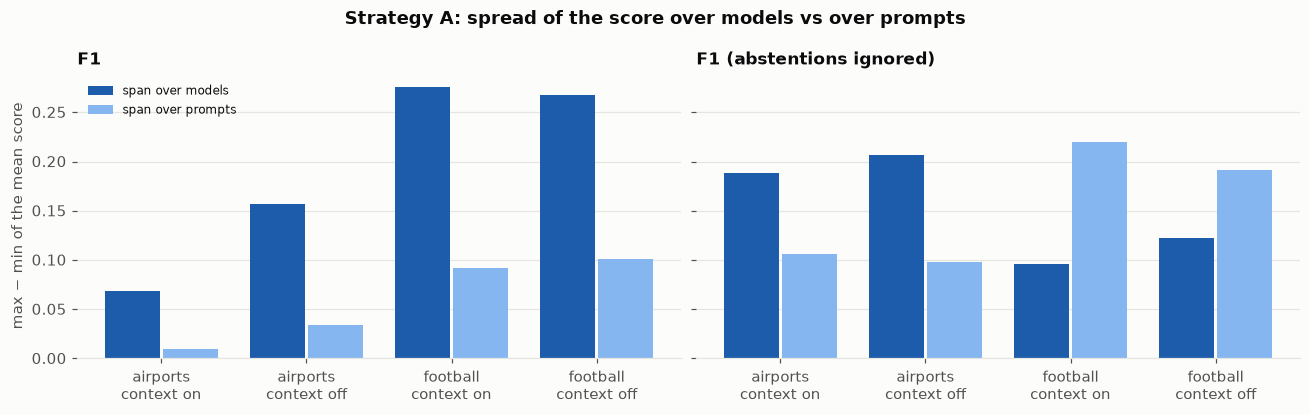

In [5]:
t = metrics(v[v.strategy == "A"], ["dataset", "set", "model", "approach"])
rows = []
for (d, s_), g in t.groupby(["dataset", "set"]):
    for sc, n in SCORES:
        pm = g.pivot(index="model", columns="approach", values=sc)
        rows.append({"dataset": d, "set": s_, "score": n, "span over models (mean over prompts)": pm.mean(axis=1).max() - pm.mean(axis=1).min(),
                     "span over prompts (mean over models)": pm.mean(axis=0).max() - pm.mean(axis=0).min()})
r = pd.DataFrame(rows); display(r)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (sc, n) in zip(axes, SCORES):
    d = r[r.score == n]; x = np.arange(len(d))
    ax.bar(x - 0.2, d["span over models (mean over prompts)"], 0.38, color="#1c5cab", label="span over models")
    ax.bar(x + 0.2, d["span over prompts (mean over models)"], 0.38, color="#86b6ef", label="span over prompts")
    ax.set_xticks(x); ax.set_xticklabels([f"{a}\ncontext {'on' if b == 'ctx' else 'off'}" for a, b in zip(d.dataset, d.set)]); ax.set_title(n); ax.grid(axis="x", visible=False)
axes[0].legend(fontsize=8); axes[0].set_ylabel("max − min of the mean score")
fig.suptitle("Strategy A: spread of the score over models vs over prompts")
save(fig, FOLDER, "both_model_vs_prompt")

For F1, the choice of model matters more than the choice of prompt on both datasets. The span over models is 0.07 (airports) and 0.28 (football) with context on, against 0.01 and 0.09 over prompts. With abstentions ignored, the picture flips on football: prompts span 0.22, more than models (0.10). Prompts mostly change *how accurate the answers given are*, while models mostly change *how many tasks are answered*.

### Is the best prompt the same on both datasets?

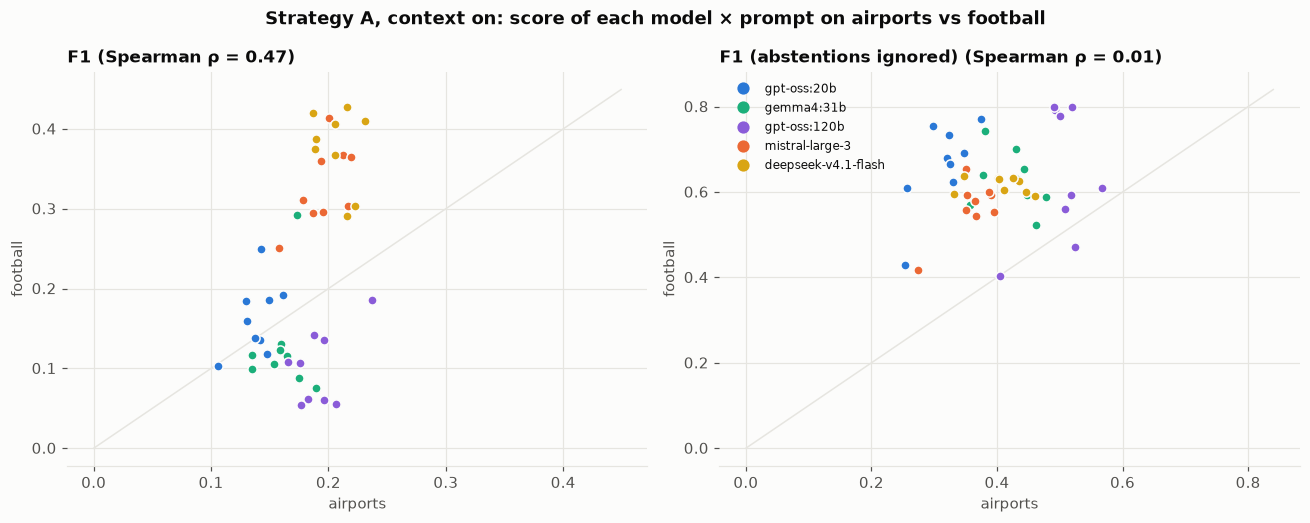

dataset,"mean rank of the prompt, airports","mean rank of the prompt, football"
approach,,
compact,4.800,3.400
zero-shot,5.200,7.800
zero-shot + CoT,4.400,7.200
1-shot,4.800,6.200
1-shot + CoT,4.800,7.000
3-shot,6.200,3.200
3-shot + CoT,5.200,4.000
5-shot,4.600,2.800
5-shot + CoT,5.000,3.400


In [6]:
t = metrics(v[(v.strategy == "A") & (v.set == "ctx")], ["dataset", "model", "approach"])
pv = t.pivot_table(index=["model", "approach"], columns="dataset", values=["f1", "f1_ign"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (s, n) in zip(axes, SCORES):
    d = pv[s].reset_index()
    for m in MODELS:
        dd = d[d.model == m]; ax.scatter(dd.airports, dd.football, color=MCOLOR[m], s=36, edgecolor=SURFACE, zorder=3)
    lim = [0, max(d.airports.max(), d.football.max()) * 1.05]; ax.plot(lim, lim, color=GRID, lw=1)
    rho = d[["airports", "football"]].rank().corr().iloc[0, 1]
    ax.set_xlabel("airports"); ax.set_ylabel("football"); ax.set_title(f"{n} (Spearman ρ = {rho:.2f})")
axes[1].legend(handles=model_handles(), fontsize=8)
fig.suptitle("Strategy A, context on: score of each model × prompt on airports vs football")
save(fig, FOLDER, "both_prompt_consistency")
rk = t.assign(rank=t.groupby(["dataset", "model"]).f1.rank(ascending=False)).pivot_table(index="approach", columns="dataset", values="rank").reindex(PROMPTS)
display(rk.rename(index=PNAME).round(1).rename(columns=lambda c: f"mean rank of the prompt, {c}"))

The ranking of model × prompt configurations transfers only partly between datasets (Spearman ρ = 0.47 for F1) and not at all for F1 ign (ρ = 0.01). On airports the mean rank of the 9 prompts is flat (4.4–6.2); on football the few-shot prompts are clearly best (5-shot mean rank 2.8, 3-shot 3.2) and zero-shot clearly worst (7.8). A prompt chosen on one graph should not be assumed best on another.

### Effect of context on both datasets (task pairs whose context differs, 9 prompts pooled)

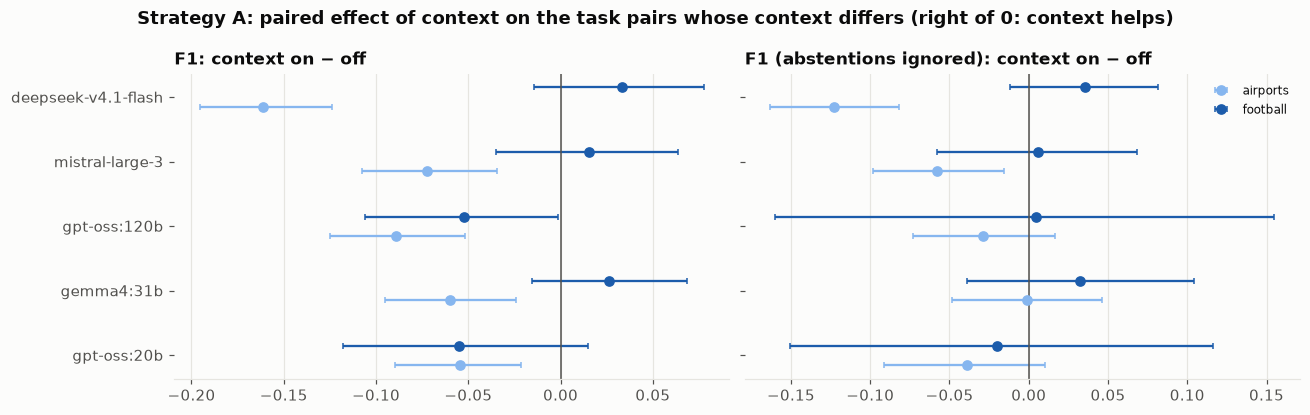

,dataset,model,score,diff,lo,hi,task pairs
0,airports,gpt-oss:20b,F1,-0.054,-0.090,-0.022,85
1,airports,gpt-oss:20b,F1 (abstentions ignored),-0.039,-0.091,0.010,85
2,airports,gemma4:31b,F1,-0.060,-0.095,-0.024,85
3,airports,gemma4:31b,F1 (abstentions ignored),-0.001,-0.049,0.046,85
4,airports,gpt-oss:120b,F1,-0.089,-0.125,-0.052,85
5,airports,gpt-oss:120b,F1 (abstentions ignored),-0.029,-0.073,0.017,85
6,airports,mistral-large-3,F1,-0.072,-0.107,-0.035,85
7,airports,mistral-large-3,F1 (abstentions ignored),-0.058,-0.098,-0.016,85
8,airports,deepseek-v4.1-flash,F1,-0.162,-0.196,-0.124,85
9,airports,deepseek-v4.1-flash,F1 (abstentions ignored),-0.123,-0.163,-0.082,85


In [7]:
rows = []
for d in DS:
    a = v[(v.dataset == d) & (v.strategy == "A")]
    pairs = context_pairs(d)   # only the pairs whose context-on G has context properties
    off = a[a.set == "noctx"].assign(task_id=lambda x: x.task_id.map(pairs)).dropna(subset=["task_id"])
    on = a[(a.set == "ctx") & a.task_id.isin(pairs.values())]
    for m in MODELS:
        x = off[off.model == m].set_index(["task_id", "approach"]).outcome
        y = on[on.model == m].set_index(["task_id", "approach"]).outcome
        for s, n in SCORES:
            dd, lo, hi = paired_diff(x, y, s); rows.append({"dataset": d, "model": m, "score": n, "diff": dd, "lo": lo, "hi": hi, "task pairs": len(pairs)})
pdf = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (s, n) in zip(axes, SCORES):
    for i, d in enumerate(DS):
        dd = pdf[(pdf.dataset == d) & (pdf.score == n)].set_index("model").reindex(MODELS)
        y = np.arange(len(MODELS)) + (i - 0.5) * 0.3
        ax.errorbar(dd["diff"], y, xerr=[dd["diff"] - dd.lo, dd.hi - dd["diff"]], fmt="o", color=DCOLOR[d], label=d, capsize=2)
    ax.axvline(0, color=INK2, lw=1); ax.set_yticks(range(len(MODELS))); ax.set_yticklabels(MN); ax.invert_yaxis(); ax.set_title(f"{n}: context on − off"); ax.grid(axis="y", visible=False)
axes[1].legend(fontsize=8)
fig.suptitle("Strategy A: paired effect of context on the task pairs whose context differs (right of 0: context helps)")
save(fig, FOLDER, "both_context_effect")
display(pdf.assign(model=pdf.model.map(MNAME)).round(3))

Context behaves differently on the two datasets. On airports, the 85 task pairs where context-on tasks replace some of the airport's own properties with properties of neighbouring nodes lose F1 for every model (−0.05 to −0.16, all significant). For F1 ign the loss is significant for mistral (−0.06) and deepseek (−0.12). On football's 33 pairs no model shows a significant change. Context properties are a weaker clue than the node's own properties, especially on airports, where an own property like the city or the ICAO prefix nearly identifies the airport.

## 3. Strategy B and A vs B

### B − A on both datasets

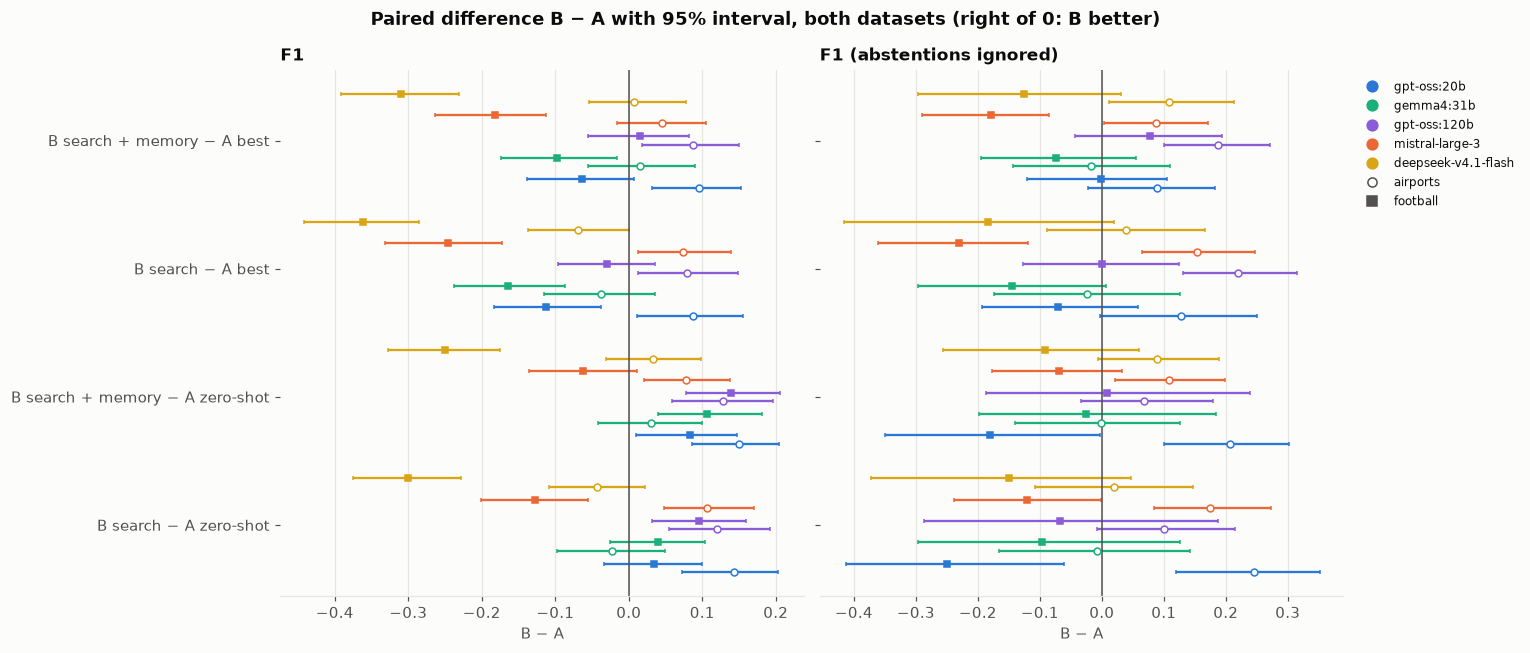

,dataset,model,pair,diff,lo,hi,only A right,only B right,p (McNemar)
0,airports,gpt-oss:20b,B search − A zero-shot,0.143,0.072,0.203,10,38,0.000
2,airports,gpt-oss:20b,B search + memory − A zero-shot,0.150,0.086,0.205,6,40,0.000
4,airports,gpt-oss:20b,B search − A best,0.088,0.011,0.156,18,36,0.020
6,airports,gpt-oss:20b,B search + memory − A best,0.095,0.031,0.152,9,33,0.000
8,airports,gemma4:31b,B search − A zero-shot,-0.022,-0.098,0.050,24,19,0.542
10,airports,gemma4:31b,B search + memory − A zero-shot,0.030,-0.042,0.099,19,27,0.302
12,airports,gemma4:31b,B search − A best,-0.037,-0.115,0.036,27,19,0.302
14,airports,gemma4:31b,B search + memory − A best,0.016,-0.055,0.090,21,26,0.560
16,airports,gpt-oss:120b,B search − A zero-shot,0.120,0.055,0.192,11,37,0.000
18,airports,gpt-oss:120b,B search + memory − A zero-shot,0.128,0.058,0.196,9,40,0.000


In [8]:
rows = []
for d in DS:
    for m in MODELS:
        for a_ in ("A zero-shot", "A best"):
            for b_ in ("B search", "B search + memory"):
                x = ctx[(ctx.dataset == d) & (ctx.model == m) & (ctx.cfg == a_)].set_index("task_id").outcome
                y = ctx[(ctx.dataset == d) & (ctx.model == m) & (ctx.cfg == b_)].set_index("task_id").outcome
                for s, n in SCORES:
                    dd, lo, hi = paired_diff(x, y, s); rows.append({"dataset": d, "model": m, "pair": f"{b_} − {a_}", "score": n, "diff": dd, "lo": lo, "hi": hi, **paired(x, y)})
pdf = pd.DataFrame(rows); pairs = pdf.pair.unique().tolist()
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for ax, (s, n) in zip(axes, SCORES):
    for i, p in enumerate(pairs):
        for j, m in enumerate(MODELS):
            for k, d in enumerate(DS):
                r = pdf[(pdf.pair == p) & (pdf.model == m) & (pdf.dataset == d) & (pdf.score == n)].iloc[0]
                y = i * 12 + j * 2 + k * 0.8
                ax.errorbar(r["diff"], y, xerr=[[r["diff"] - r.lo], [r.hi - r["diff"]]], fmt="o" if d == "airports" else "s", color=MCOLOR[m],
                            mfc=MCOLOR[m] if d == "football" else "white", ms=4.5, capsize=1.5)
    ax.axvline(0, color=INK2, lw=1); ax.set_title(n); ax.set_xlabel("B − A")
    ax.set_yticks([i * 12 + 4.4 for i in range(len(pairs))]); ax.set_yticklabels(pairs); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
h = model_handles() + [plt.Line2D([], [], ls="", marker="o", mfc="white", color=INK2, label="airports"), plt.Line2D([], [], ls="", marker="s", color=INK2, label="football")]
axes[1].legend(handles=h, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.suptitle("Paired difference B − A with 95% interval, both datasets (right of 0: B better)")
save(fig, FOLDER, "both_ab_forest")
display(pdf[pdf.score == "F1"].assign(model=lambda x: x.model.map(MNAME))[["dataset", "model", "pair", "diff", "lo", "hi", "only first right", "only second right", "p (McNemar)"]]
        .rename(columns={"only first right": "only A right", "only second right": "only B right"}).round(3))

Task by task, B − A is mostly positive on airports and mostly negative on football. On airports, B search beats A zero-shot significantly for gpt-oss:20b, gpt-oss:120b and mistral (+0.11 to +0.14 F1), and B + memory beats A best for gpt-oss:20b (+0.10) and gpt-oss:120b (+0.09). On football, B is significantly worse than A best for gemma4, mistral and deepseek (−0.10 to −0.36), and the only significant gains of B are over the zero-shot prompt of the cautious models.

### What memory adds to B on both datasets

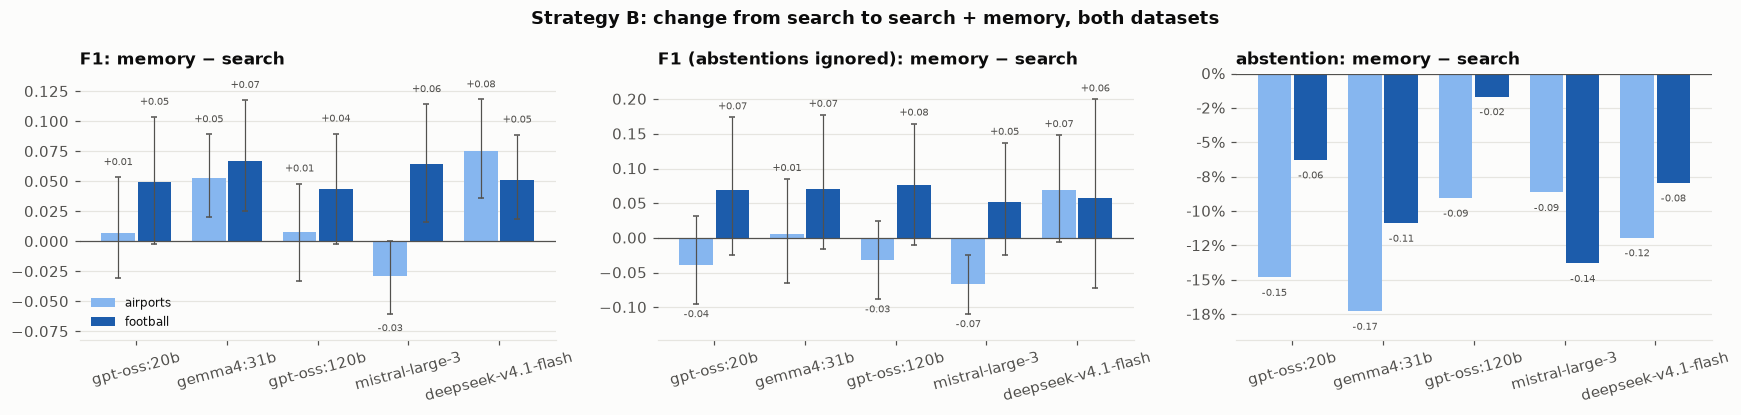

In [9]:
rows = []
for d in DS:
    for m in MODELS:
        x = ctx[(ctx.dataset == d) & (ctx.model == m) & (ctx.cfg == "B search")].set_index("task_id").outcome
        y = ctx[(ctx.dataset == d) & (ctx.model == m) & (ctx.cfg == "B search + memory")].set_index("task_id").outcome
        for s, n in SCORES + [("abstention", "abstention")]:
            if s == "abstention":
                dd = (y == "abstained").mean() - (x == "abstained").mean(); lo = hi = np.nan
            else:
                dd, lo, hi = paired_diff(x, y, s)
            rows.append({"dataset": d, "model": m, "score": n, "diff": dd, "lo": lo, "hi": hi})
pdf = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, (s, n) in zip(axes, SCORES + [("abstention", "abstention")]):
    t = pdf[pdf.score == n].rename(columns={"diff": "val", "lo": "val_lo", "hi": "val_hi"})
    grouped_bars(ax, t, "model", MODELS, "dataset", DS, "val", DCOLOR, names=MNAME, err=s != "abstention", fmt="{:+.2f}")
    ax.axhline(0, color=INK2, lw=0.8); ax.set_title(f"{n}: memory − search"); ax.set_xticklabels(MN, rotation=15)
axes[0].legend(fontsize=8); pct(axes[2])
fig.suptitle("Strategy B: change from search to search + memory, both datasets")
save(fig, FOLDER, "both_memory_gain")

Allowing memory on the same evidence is a safer gain on football than on airports. On football, F1 rises for every model (+0.04 to +0.07) with modest drops in abstention. On airports, F1 rises for gemma4 (+0.05) and deepseek (+0.08), is unchanged for the gpt-oss models and falls for mistral (−0.03), even though abstention falls by 9–17 points. With abstentions ignored, memory lowers precision for three models on airports and raises it for all five on football: on airports the evidence is usually better than the model's memory, on football it is not.

### Retrieval on both datasets

,dataset,model,plan names an entity,plan names the right node,run answers,evidence truncated
0,airports,gpt-oss:20b,0.362,0.084,0.392,0.638
1,airports,gemma4:31b,0.347,0.119,0.269,0.144
2,airports,gpt-oss:120b,0.306,0.145,0.351,0.930
3,airports,mistral-large-3,0.587,0.204,0.521,0.975
4,airports,deepseek-v4.1-flash,0.365,0.167,0.280,0.908
5,football,gpt-oss:20b,0.120,0.102,0.232,0.759
6,football,gemma4:31b,0.113,0.107,0.216,0.537
7,football,gpt-oss:120b,0.120,0.106,0.233,0.987
8,football,mistral-large-3,0.170,0.117,0.303,0.996
9,football,deepseek-v4.1-flash,0.146,0.119,0.075,0.980


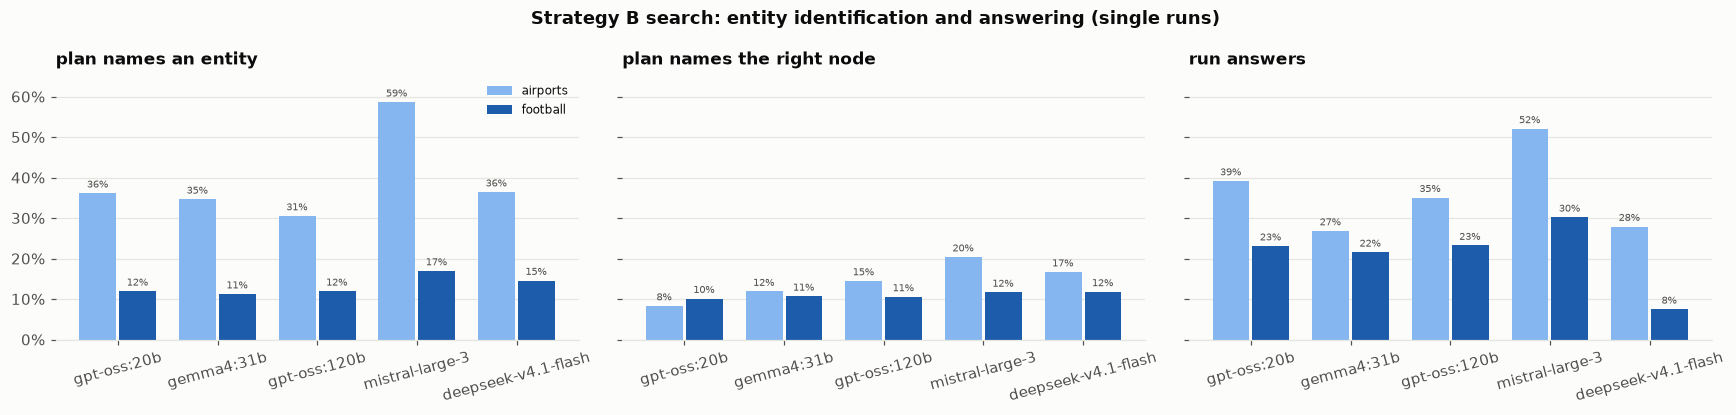

In [10]:
rows = []
for d in DS:
    det = load_b_detail(d); det = det[det.variant == "search_evidence"]
    for m in MODELS:
        x = det[det.model == m]
        rows.append({"dataset": d, "model": m, "plan names an entity": x.entity_named.mean(), "plan names the right node": x.entity_match.mean(),
                     "run answers": x.answered.mean(), "evidence truncated": x.evidence_truncated.mean()})
t = pd.DataFrame(rows); display(t.assign(model=t.model.map(MNAME)).round(3))
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for ax, c in zip(axes, ["plan names an entity", "plan names the right node", "run answers"]):
    grouped_bars(ax, t, "model", MODELS, "dataset", DS, c, DCOLOR, names=MNAME, err=False, fmt="{:.0%}")
    ax.set_title(c); pct(ax); ax.set_xticklabels(MN, rotation=15)
axes[0].legend(fontsize=8)
fig.suptitle("Strategy B search: entity identification and answering (single runs)")
save(fig, FOLDER, "both_retrieval")

The agent identifies the entity much more often on airports. Its plan names an entity in 31–59% of airport runs (8–20% the right airport), against 11–17% of football runs (10–12% the right player, almost only when the name is given). Airports give the agent usable search keys (codes, cities, coordinates) where football's given properties are season statistics. Answer rates follow: 27–52% of airport runs answer, against 8–30% on football.

### Concentration of the evidence sources

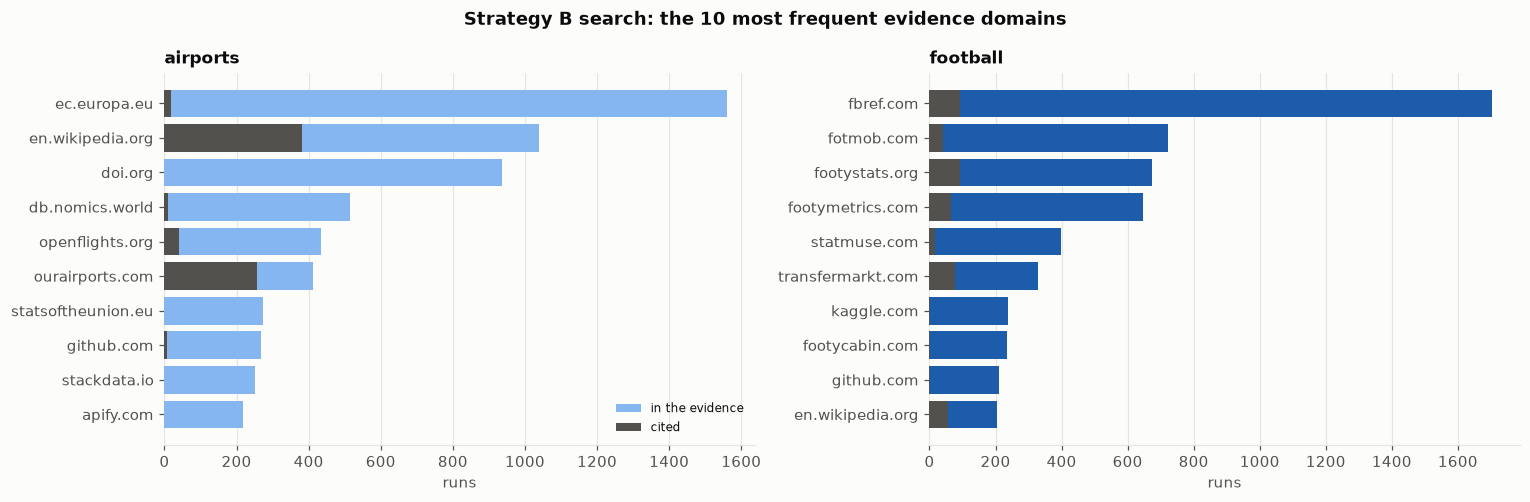

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, d in zip(axes, DS):
    dom = load_domains(d); dd = dom[dom.variant == "search_evidence"].groupby("domain")[["passed", "cited"]].sum().sort_values("passed", ascending=False).head(10)
    y = np.arange(len(dd))
    ax.barh(y, dd.passed, color=DCOLOR[d], label="in the evidence"); ax.barh(y, dd.cited, color=INK2, label="cited")
    ax.set_yticks(y); ax.set_yticklabels(dd.index); ax.invert_yaxis(); ax.set_title(d); ax.grid(axis="y", visible=False); ax.set_xlabel("runs")
axes[0].legend(fontsize=8)
fig.suptitle("Strategy B search: the 10 most frequent evidence domains")
save(fig, FOLDER, "both_domains")

Both datasets draw evidence from a long tail (1,955 domains for airports, 1,174 for football; the top 5 hold 26% and 30% of the evidence slots). The cited sources differ in quality: on airports, en.wikipedia.org and ourairports.com account for most citations and are reference sources for exactly the stored facts. On football, the citations spread over statistics aggregators (fbref, footystats, transfermarkt, footymetrics) that disagree by season and competition.

## 4. Task factors on both datasets

### Score per stratum, A best and B + memory

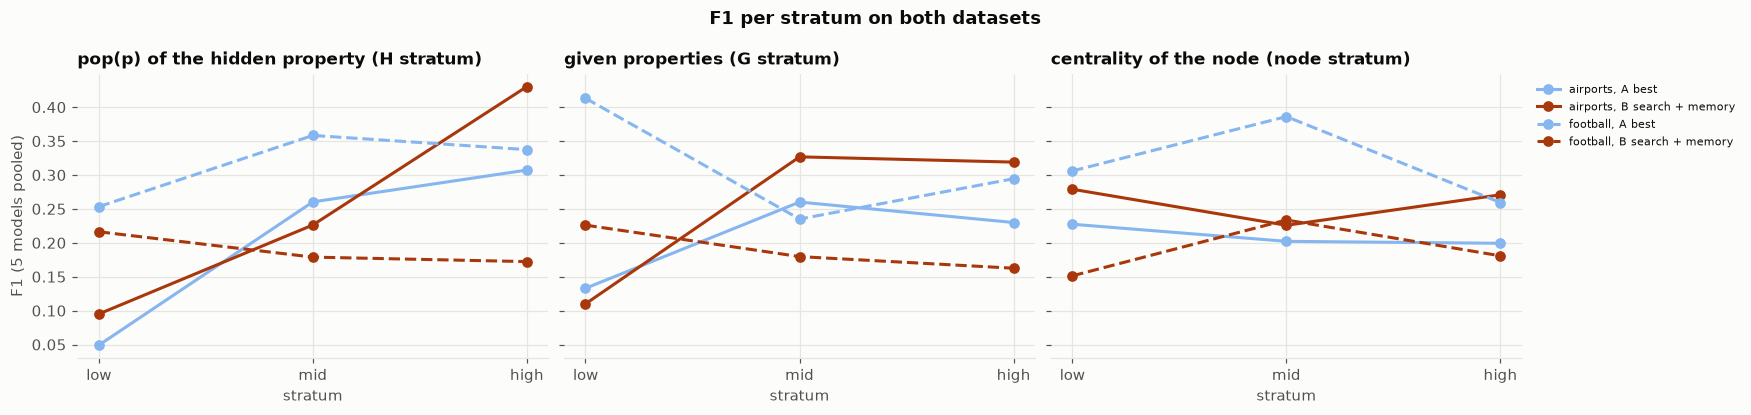

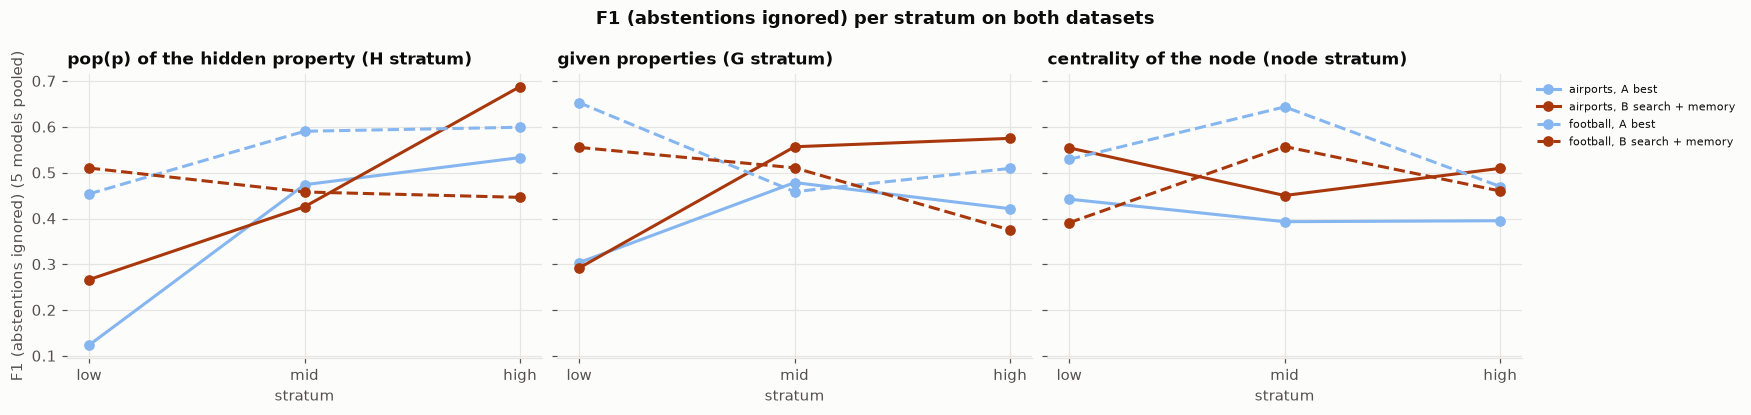

In [12]:
for s, n in SCORES:
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
    for ax, (f, fn) in zip(axes, FACTORS.items()):
        for d, ls in zip(DS, ("-", "--")):
            for c_ in ("A best", "B search + memory"):
                t = metrics(ctx[(ctx.dataset == d) & (ctx.cfg == c_)], [f]).set_index(f).reindex(STRATA)
                ax.plot(STRATA, t[s], ls=ls, marker="o", lw=2, color=CC[c_], label=f"{d}, {c_}")
        ax.set_title(fn); ax.set_xlabel("stratum")
    axes[0].set_ylabel(f"{n} (5 models pooled)"); axes[-1].legend(fontsize=7.5, loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.suptitle(f"{n} per stratum on both datasets")
    save(fig, FOLDER, f"both_strata_{s}")

The popularity of the hidden property orders difficulty on airports but not on football. On airports, F1 rises from the low to the high H stratum for both A best (0.05 → 0.31) and B + memory (0.10 → 0.43), and the gain from search is largest for popular properties. On football the H strata are flat or inverted (A best 0.25–0.36, B + memory 0.17–0.22). G and node-centrality strata give no consistent pattern on either dataset.

### Score against difficulty (within-dataset tertiles)

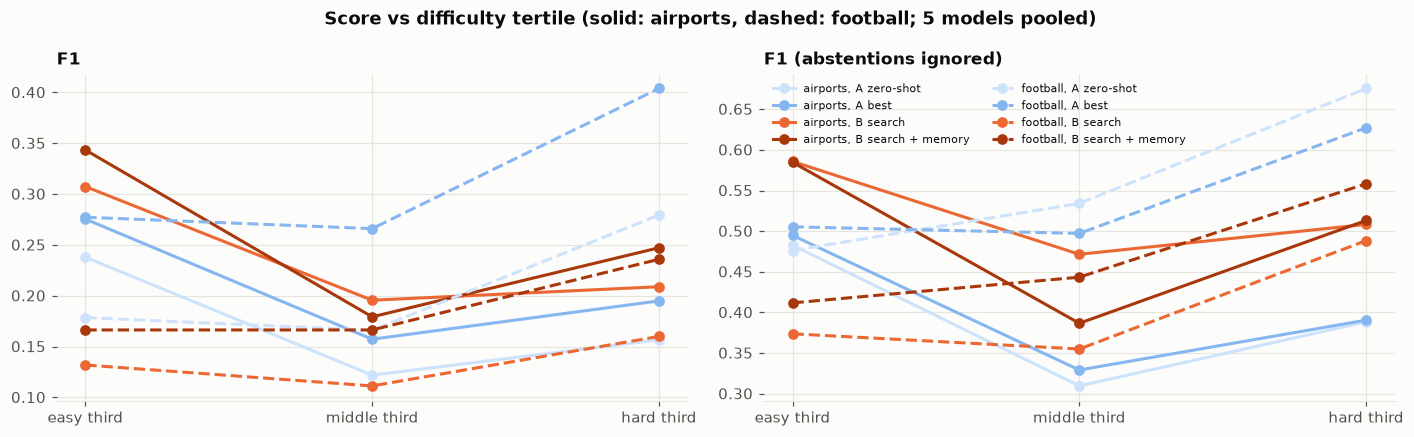

In [13]:
d = ctx[ctx.cfg.notna()].copy()
d["bin"] = d.groupby("dataset").difficulty.transform(lambda x: pd.qcut(x, 3, labels=["easy third", "middle third", "hard third"]).astype(str))
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=False)
B3 = ["easy third", "middle third", "hard third"]
for ax, (s, n) in zip(axes, SCORES):
    for ds, ls in zip(DS, ("-", "--")):
        for c_ in C:
            t = metrics(d[(d.dataset == ds) & (d.cfg == c_)], ["bin"]).set_index("bin").reindex(B3)
            ax.plot(B3, t[s], ls=ls, marker="o", color=CC[c_], lw=2, label=f"{ds}, {c_}")
    ax.set_title(n)
axes[1].legend(fontsize=7, ncol=2)
fig.suptitle("Score vs difficulty tertile (solid: airports, dashed: football; 5 models pooled)")
save(fig, FOLDER, "both_difficulty")

The difficulty score works as intended on airports, where the easiest tertile scores highest for every approach (A best 0.28, B + memory 0.34). On football it does not: the hardest tertile scores highest for every approach (A best 0.40, B + memory 0.24). The difficulty measure, built from popularity and centrality, captures how rare the information is in the graph, not how hard it is to guess or retrieve. On football these two diverge.

### Score against pop(p) of the hidden property

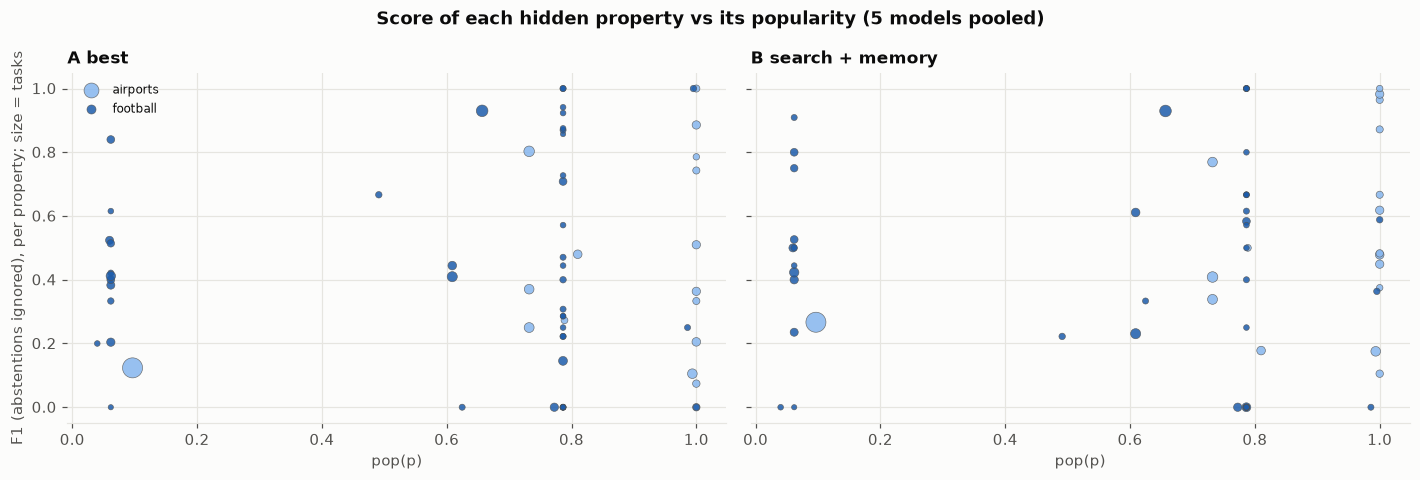

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, c_ in zip(axes, ["A best", "B search + memory"]):
    for d in DS:
        pop = popularity(d).set_index("property").popularity
        t = metrics(ctx[(ctx.dataset == d) & (ctx.cfg == c_)], ["property"]).assign(pop=lambda x: x.property.map(pop))
        ax.scatter(t["pop"], t.f1_ign, s=10 + 2 * t.tasks / 5, color=DCOLOR[d], edgecolor=INK2, linewidth=0.4, alpha=0.85, label=d)
    ax.set_xlabel("pop(p)"); ax.set_title(c_)
axes[0].set_ylabel("F1 (abstentions ignored), per property; size = tasks"); axes[0].legend(fontsize=8)
fig.suptitle("Score of each hidden property vs its popularity (5 models pooled)")
save(fig, FOLDER, "both_popularity")

Per property, popularity explains much of the airports scores: the one low-popularity property (commercial_flights, pop = 0.10) is the hardest. Football's properties cluster at pop ≈ 0.06 (goalkeeper statistics) and ≈ 0.79 (outfield statistics) with scores from 0 to above 0.9 inside each cluster.

## 5. Effort on both datasets

### Energy per run and score

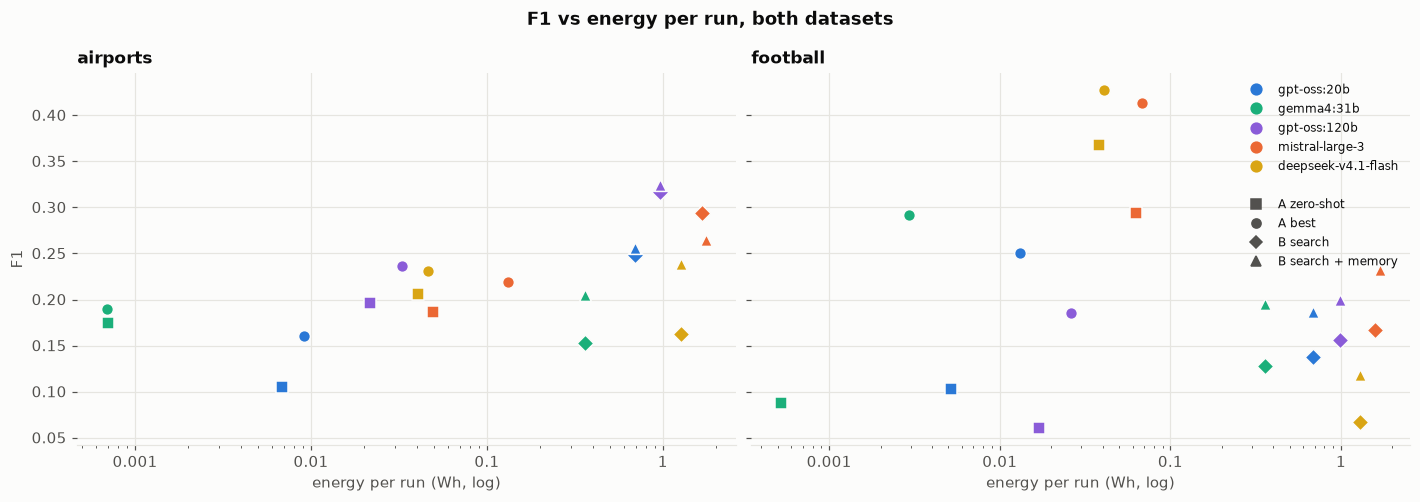

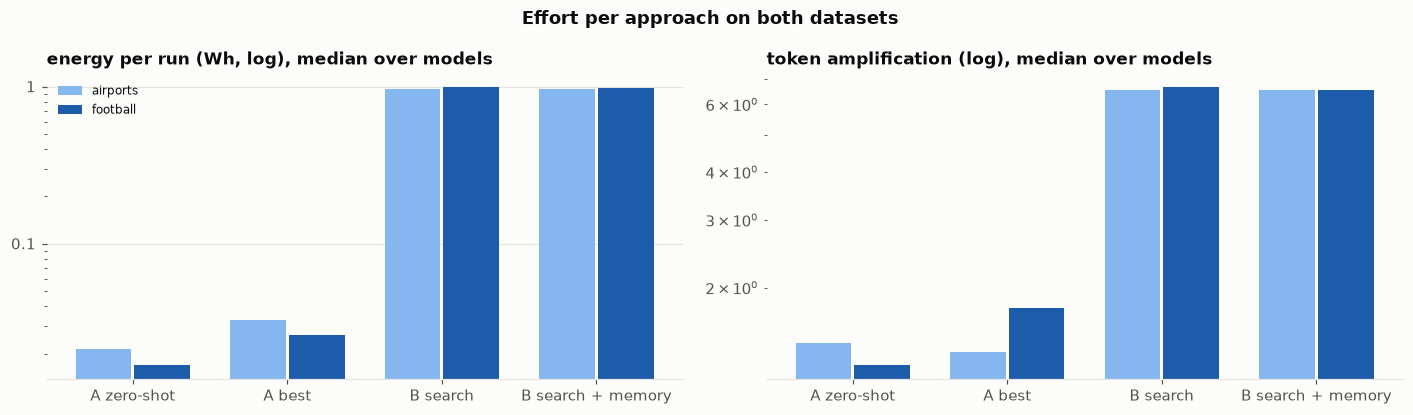

EC                                           amp                                       
cfg                          A best A zero-shot B search B search + memory A best A zero-shot B search B search + memory
dataset  model                                                                                                          
airports deepseek-v4.1-flash  0.047       0.040    1.272             1.276  1.209       1.338    6.381             6.273
         gemma4:31b           0.001       0.001    0.362             0.362  1.363       1.434    5.702             5.608
         gpt-oss:120b         0.033       0.021    0.966             0.967  3.192       1.966    6.933             6.818
         gpt-oss:20b          0.009       0.007    0.691             0.692  1.744       2.114    6.545             6.538
         mistral-large-3      0.132       0.049    1.671             1.753  1.313       1.369    7.214             7.140
football deepseek-v4.1-flash  0.041       0.038    1.297             1.298  1.141       1.185    6.338             6.229
         gemma4:31b           0.003       0.001    0.359             0.359  1.766       1.258    6.453             6.341
         gpt-oss:120b         0.026       0.017    0.988             0.986  2.834       1.750    6.921             6.779
         gpt-oss:20b          0.013       0.005    0.681             0.681  3.856       1.834    6.636             6.518
         mistral-large-3      0.069       0.063    1.577             1.686  1.116       1.208    7.008             6.972

In [15]:
e = eff[eff.set == "ctx"].copy()
e["cfg"] = None
for (d, m), p in BEST.items():
    e.loc[(e.dataset == d) & (e.model == m) & (e.strategy == "A") & (e.approach == p), "cfg"] = "A best"
e.loc[(e.strategy == "A") & (e.approach == "zero") & e.cfg.isna(), "cfg"] = "A zero-shot"
e.loc[e.approach == "search_evidence", "cfg"] = "B search"; e.loc[e.approach == "search_memory", "cfg"] = "B search + memory"
g = e[e.cfg.notna()].groupby(["dataset", "model", "cfg"]).agg(EC=("EC_run", "mean"), proc=("tokens_proc", "sum"), user=("tokens_user", "sum"), latency=("latency_s", "mean")).reset_index()
g["amp"] = g.proc / g.user
t = metrics(ctx[ctx.cfg.notna()], ["dataset", "model", "cfg"]).merge(g, on=["dataset", "model", "cfg"])
MK = {"A zero-shot": "s", "A best": "o", "B search": "D", "B search + memory": "^"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, d in zip(axes, DS):
    for _, r in t[t.dataset == d].iterrows():
        ax.scatter(r.EC, r.f1, marker=MK[r.cfg], s=60, color=MCOLOR[r.model], edgecolor=SURFACE, zorder=3)
    logaxis(ax, "x"); ax.set_xlabel("energy per run (Wh, log)"); ax.set_title(d)
axes[0].set_ylabel("F1")
h = model_handles() + [plt.Line2D([], [], ls="", marker="", label="")] + [plt.Line2D([], [], ls="", marker=mk, color=INK2, label=c) for c, mk in MK.items()]
axes[1].legend(handles=h, fontsize=8)
fig.suptitle("F1 vs energy per run, both datasets")
save(fig, FOLDER, "both_energy_f1")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, (c, n) in zip(axes, [("EC", "energy per run (Wh, log)"), ("amp", "token amplification (log)")]):
    pv = t.pivot_table(index="cfg", columns="dataset", values=c, aggfunc="median").reindex(C)
    x = np.arange(len(C))
    for i, d in enumerate(DS):
        ax.bar(x + (i - 0.5) * 0.38, pv[d], 0.36, color=DCOLOR[d], label=d)
    logaxis(ax, "y"); ax.set_xticks(x); ax.set_xticklabels(C); ax.set_title(n + ", median over models"); ax.grid(axis="x", visible=False)
axes[0].legend(fontsize=8)
fig.suptitle("Effort per approach on both datasets")
save(fig, FOLDER, "both_effort")
display(t.assign(model=t.model.map(MNAME)).pivot_table(index=["dataset", "model"], columns="cfg", values=["EC", "amp"]).round(4))

The cost structure is the same on both datasets. A run of B takes 0.36–1.75 Wh, most of it in web searches, against 0.001–0.13 Wh for the model's best A prompt (roughly 10–400×). Token amplification is 5.6–7.2× for B and 1.1–3.9× for A. On airports this extra energy buys a higher F1 for four models; on football it buys a lower F1 for four.

### Run agreement on both datasets

,dataset,cfg,same outcome in all runs
0,airports,A best,0.692
1,airports,A zero-shot,0.793
2,airports,B search,0.707
3,airports,B search + memory,0.672
4,football,A best,0.603
5,football,A zero-shot,0.832
6,football,B search,0.714
7,football,B search + memory,0.672


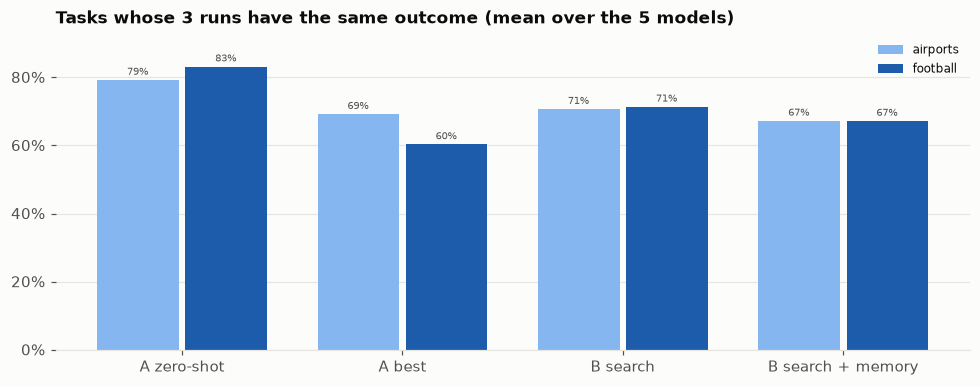

In [16]:
r = runs.copy()
r["cfg"] = r.apply(cfg, axis=1)
ag = agreement(r[r.cfg.notna()], ["dataset", "cfg", "model"]).groupby(["dataset", "cfg"])["same outcome in all runs"].mean().reset_index()
fig, ax = plt.subplots(figsize=(9, 3.6))
grouped_bars(ax, ag, "cfg", C, "dataset", DS, "same outcome in all runs", DCOLOR, err=False, fmt="{:.0%}")
pct(ax); ax.legend(fontsize=8); ax.set_title("Tasks whose 3 runs have the same outcome (mean over the 5 models)")
display(ag.round(3))
save(fig, FOLDER, "both_stability")

Run-to-run stability is similar on both datasets: on average over the models, the 3 runs agree on the outcome for 67–71% of the tasks with B, 60–69% with the A best prompt and 79–83% with A zero-shot. The lower stability of A best comes from the compact prompt, which several models prefer and which is the least stable.

## Takeaways

1. **Whether search helps depends on the dataset.** B + memory beats the best A prompt on airports for 4 of 5 models (F1 0.21–0.32 vs 0.16–0.24) and loses to it on football for 4 of 5 (0.12–0.23 vs 0.19–0.43).
2. **Entity identification decides B's success.** The agent names the right node in 8–20% of airport runs but 10–12% of football runs, and on football almost only when the name is given.
3. **The model matters more than the prompt for F1 on both datasets** (span 0.07–0.28 vs 0.01–0.09), but prompt rankings transfer poorly between datasets (ρ = 0.47 for F1, 0.01 for F1 ign).
4. **Context hurts on airports and is neutral on football** when it replaces the node's own properties (airports ΔF1 −0.05 to −0.16 for all models).
5. **The difficulty measure transfers poorly.** Popularity orders airport tasks but not football tasks, where guessable typical values dominate.
6. **Memory is a consistent, cheap improvement for B on football** (+0.04 to +0.07 F1 for all models) and a mixed one on airports.
7. **B costs roughly 10–400× the energy of A** and amplifies the user's input 6–7×, on both datasets.